# 2. Análisis exploratorio de datos

En este capítulo examinamos si Avazu es adecuado para entrenar y comparar clasificadores de clics y qué decisiones de preprocesamiento y de validación exige. Todas las consultas se hacen con DuckDB sobre el Parquet completo, sin cargar los 40 millones de filas en memoria. Usamos la ventana de entrenamiento (días 21 a 28) para todo lo que puede influir en el modelo; del día de prueba solo usamos las distribuciones de las variables de entrada, para medir la deriva. Cada sección termina con los hallazgos y las decisiones que se derivan de ellos.

| § | Pregunta | Método |
|---|---|---|
| 2.1 | ¿Cómo se cargan los datos de forma eficiente y qué tipos y faltantes tienen? | Parquet particionado, DuckDB, lectura perezosa con Polars |
| 2.2 | ¿Cuál es la tasa base de clics y cómo cambia entre días? | Conteos y CTR por día |
| 2.3 | ¿Cómo varía el CTR con la hora, la franja y el día de la semana? | Variables derivadas de `hour` |
| 2.4 | ¿Qué cardinalidad y qué cola larga tienen las variables? | Curva de frecuencia acumulada, categorías vistas una vez |
| 2.5 | ¿Cómo se distribuyen las principales categóricas? | Frecuencias y CTR por categoría |
| 2.6 | ¿Qué forma tienen las variables numéricas derivadas? | Histogramas de log(1 + frecuencia) |
| 2.7 | ¿Qué variables se asocian con el clic y entre sí? | Información mutua, V de Cramér, Spearman |
| 2.8 | ¿Cambian las distribuciones entre entrenamiento y prueba? | Índice de estabilidad poblacional (PSI) |
| 2.9 | ¿Cómo quedan la partición y los grupos de variables? | Partición temporal, umbral de cardinalidad |

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config as C
from src import plots as P
from src import report as R
from src.persist import load_json

P.setup()
C.ensure_dirs()
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 90)
print("Resultados:", C.RESULTS.relative_to(C.ROOT), "| prueba de humo:", C.SMOKE)

import json
import polars as pl
from src import data as D, eda as E, features as F

c = E.con()
OUT = C.EDA_OUT

Resultados: results | prueba de humo: False


## 2.1 Carga eficiente, tipos y valores faltantes

El archivo original es un CSV comprimido con gzip. Lo convertimos una sola vez a Parquet particionado por día con DuckDB (`python -m src.runner prepare`). Durante la conversión derivamos las variables temporales y una clave de muestreo $u \in [0, 1)$, calculada como el hash del identificador de cada fila. Las muestras de $n$ filas son las $n$ filas con menor $u$: son reproducibles, son idénticas en scikit-learn y en PySpark y están anidadas, de modo que la muestra de 100 mil filas está contenida en la de un millón.

Guardamos todas las categóricas como texto, incluidas las anonimizadas que parecen numéricas (`C1`, `C14`–`C21`), porque sus valores son códigos sin orden.

In [2]:
man = D.load_manifest()
conv = load_json(C.COMMON / "conversion_parquet.json") if (C.COMMON / "conversion_parquet.json").exists() else {}
pq_bytes = sum(f["bytes"] for f in man["archivos_parquet"])
tabla = E.schema_and_missing(c)
display(tabla.set_index("variable").T)

# Lectura perezosa: Polars solo lee las columnas y las particiones que la consulta necesita
lf = D.scan().filter(pl.col("day").is_in(C.TRAIN_DAYS)).group_by("day").agg(pl.len().alias("filas"), pl.col("click").mean().alias("ctr"))
print(lf.explain().splitlines()[-1][:160])
print(f"Conversión: {R.secs(conv['conversion_s']) if 'conversion_s' in conv else 'sin registro'} | CSV.gz: {man['raw']['bytes'] / 1024**3:.2f} GB | Parquet: {pq_bytes / 1024**3:.2f} GB")

variable,click,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,...,C17,C18,C19,C20,C21,hora,dia_semana,franja,u,day
tipo,TINYINT,INTEGER,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,...,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,DOUBLE,BIGINT
nulos,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


END UNION[maintain_order: false]
Conversión: 108.9 s | CSV.gz: 1.04 GB | Parquet: 0.88 GB


In [3]:
nulos = int(tabla["nulos"].sum())
con_nulos = tabla.loc[tabla["nulos"] > 0, "variable"].tolist()
t_conv = (f"La conversión a Parquet tomó {R.secs(conv['conversion_s'])} y el" if "conversion_s" in conv else "El")
R.findings(
    f"{t_conv} Parquet ocupa {pq_bytes / man['raw']['bytes']:.2f} veces el tamaño del CSV comprimido. "
    + ("No hay valores nulos en ninguna variable." if nulos == 0 else
       f"Hay {R.num(nulos)} valores nulos, concentrados en {', '.join(con_nulos)}."),
    {"Preprocesamiento": "leemos siempre desde el Parquet, con selección de columnas y filtro por día; las categóricas se tratan como texto.",
     "Modelado": "no se requiere imputación" + ("." if nulos == 0 else "; los nulos se tratan como una categoría propia."),
     "Riesgos": "la ausencia de nulos no descarta valores faltantes codificados como una categoría frecuente; la sección 2.4 revisa los valores dominantes."})

### Hallazgos y decisiones

La conversión a Parquet tomó 108.9 s y el Parquet ocupa 0.84 veces el tamaño del CSV comprimido. No hay valores nulos en ninguna variable.

- **Preprocesamiento:** leemos siempre desde el Parquet, con selección de columnas y filtro por día; las categóricas se tratan como texto.
- **Modelado:** no se requiere imputación.
- **Riesgos:** la ausencia de nulos no descarta valores faltantes codificados como una categoría frecuente; la sección 2.4 revisa los valores dominantes.


## 2.2 Variable objetivo y tasa base

Medimos el desbalance con la razón $IR = n_0 / n_1$ entre impresiones sin clic y con clic. La tasa de clics por día incluye la validación (día 29) pero no la prueba (día 30).

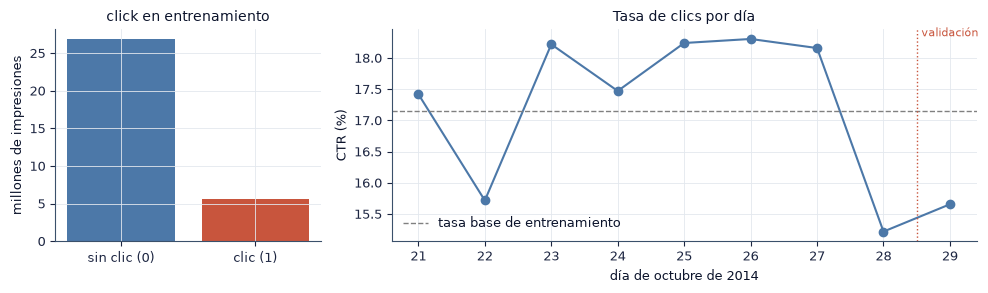

día,21,22,23,24,25,26,27,28,29
impresiones,4.1230e+06,5.3371e+06,3.8708e+06,3.3353e+06,3.3631e+06,3835892.0,3.2250e+06,5.2872e+06,3.8326e+06
CTR (%),1.7420e+01,1.5720e+01,1.8220e+01,1.7470e+01,1.8240e+01,18.3,1.8160e+01,1.5220e+01,1.5660e+01


In [4]:
dia = E.ctr_by(c, "day", f"{E.TRAIN},{C.VAL_DAY}")
n1 = int((dia["n"] * dia["ctr"])[dia["day"] <= C.TRAIN_DAYS[-1]].sum())
n_tr = int(dia.loc[dia["day"] <= C.TRAIN_DAYS[-1], "n"].sum())
base = n1 / n_tr
IR = (n_tr - n1) / n1

fig, axes = plt.subplots(1, 2, figsize=(10, 3), gridspec_kw={"width_ratios": [1, 2.2]})
axes[0].bar(["sin clic (0)", "clic (1)"], [(n_tr - n1) / 1e6, n1 / 1e6], color=[C.BAR, C.ACCENT])
axes[0].set_ylabel("millones de impresiones"); axes[0].set_title("click en entrenamiento")
axes[1].plot(dia["day"], 100 * dia["ctr"], marker="o", color=C.BAR)
axes[1].axhline(100 * base, ls="--", c="gray", lw=1, label="tasa base de entrenamiento")
axes[1].axvline(C.TRAIN_DAYS[-1] + 0.5, c=C.ACCENT, lw=1, ls=":")
axes[1].text(C.VAL_DAY, 100 * dia["ctr"].max(), "validación", ha="center", va="bottom", fontsize=8, color=C.ACCENT)
axes[1].set_xlabel("día de octubre de 2014"); axes[1].set_ylabel("CTR (%)"); axes[1].set_title("Tasa de clics por día")
axes[1].set_xticks(dia["day"]); axes[1].legend()
fig.tight_layout(); P.save(fig, "2_2_objetivo"); plt.show()
display(dia.assign(ctr=lambda t: (100 * t["ctr"]).round(2)).rename(columns={"day": "día", "n": "impresiones", "ctr": "CTR (%)"}).set_index("día").T)

In [5]:
lo, hi = dia["ctr"].min(), dia["ctr"].max()
R.findings(
    f"En entrenamiento hay {R.num(n1)} clics en {R.num(n_tr)} impresiones: la tasa base es {R.pct(base, 2)} y la razón de desbalance "
    f"es {IR:.1f}. La tasa diaria varía entre {R.pct(lo, 2)} (día {int(dia.loc[dia['ctr'].idxmin(), 'day'])}) y "
    f"{R.pct(hi, 2)} (día {int(dia.loc[dia['ctr'].idxmax(), 'day'])}); la validación registra {R.pct(dia.loc[dia['day'] == C.VAL_DAY, 'ctr'].iat[0], 2)}.",
    {"Preprocesamiento": "no remuestreamos: la ponderación por clase es una ablación (sección 6.7) y el entrenamiento principal conserva la tasa real, para que las probabilidades queden calibradas.",
     "Modelado": "con este desbalance la accuracy de referencia (predecir siempre 0) es " + R.pct(1 - base, 1) + "; por eso la métrica primaria es el ROC AUC y reportamos PR AUC, log loss y calibración. El umbral de decisión se elige en validación.",
     "Riesgos": "la variación diaria del CTR anticipa deriva temporal: un modelo calibrado en los días 21 a 28 puede quedar desplazado en el día 30."})

### Hallazgos y decisiones

En entrenamiento hay 5 550 840 clics en 32 377 421 impresiones: la tasa base es 17.14 % y la razón de desbalance es 4.8. La tasa diaria varía entre 15.22 % (día 28) y 18.30 % (día 26); la validación registra 15.66 %.

- **Preprocesamiento:** no remuestreamos: la ponderación por clase es una ablación (sección 6.7) y el entrenamiento principal conserva la tasa real, para que las probabilidades queden calibradas.
- **Modelado:** con este desbalance la accuracy de referencia (predecir siempre 0) es 82.9 %; por eso la métrica primaria es el ROC AUC y reportamos PR AUC, log loss y calibración. El umbral de decisión se elige en validación.
- **Riesgos:** la variación diaria del CTR anticipa deriva temporal: un modelo calibrado en los días 21 a 28 puede quedar desplazado en el día 30.


## 2.3 Variables temporales

De `hour` (formato AAMMDDHH) derivamos tres variables: `hora` (0 a 23), `dia_semana` (código de DuckDB, 0 = domingo) y `franja` (madrugada 0–5 h, mañana 6–11 h, tarde 12–17 h y noche 18–23 h). No usamos el día del mes como variable, porque los días de prueba no aparecen en entrenamiento.

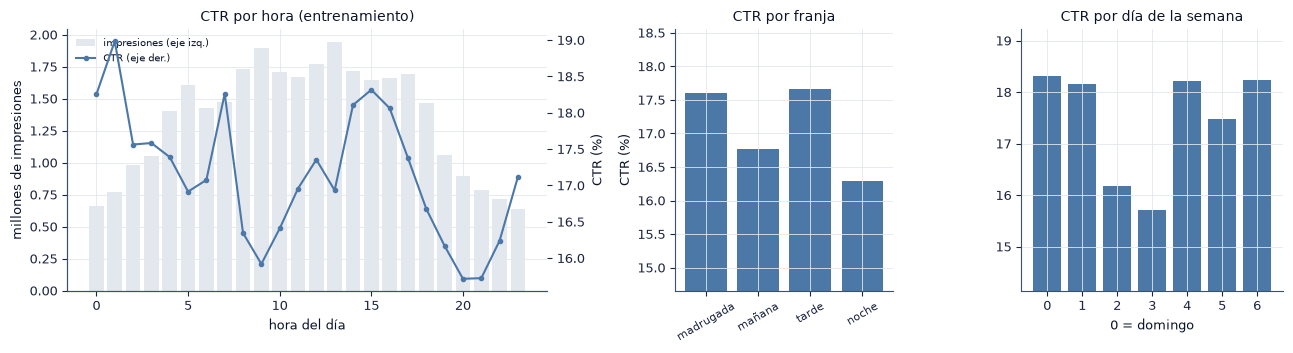

In [6]:
hora = c.execute("SELECT CAST(hora AS INTEGER) AS hora, count(*) AS n, avg(click) AS ctr FROM train GROUP BY 1 ORDER BY 1").df()
franja = c.execute("SELECT franja, count(*) AS n, avg(click) AS ctr FROM train GROUP BY 1").df()
franja = franja.set_index("franja").loc[list(C.FRANJAS)].reset_index()
sem = c.execute("SELECT dia_semana, count(*) AS n, avg(click) AS ctr FROM train GROUP BY 1 ORDER BY 1").df()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2.2, 1, 1.2]})
ax = axes[0]
ax.bar(hora["hora"], hora["n"] / 1e6, color="#E3E8EE", label="impresiones")
ax.set_ylabel("millones de impresiones"); ax.set_xlabel("hora del día")
ax2 = ax.twinx(); ax2.plot(hora["hora"], 100 * hora["ctr"], marker="o", ms=3, color=C.BAR, label="CTR")
ax2.set_ylabel("CTR (%)"); ax2.grid(False); ax.set_title("CTR por hora (entrenamiento)")
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
ax.legend(handles=[Patch(facecolor="#E3E8EE", label="impresiones (eje izq.)"), Line2D([], [], color=C.BAR, marker="o", ms=3, label="CTR (eje der.)")], fontsize=7, loc="upper left")
axes[1].bar(franja["franja"], 100 * franja["ctr"], color=C.BAR); axes[1].set_title("CTR por franja"); axes[1].set_ylabel("CTR (%)"); axes[1].tick_params(axis="x", rotation=30, labelsize=8)
axes[1].set_ylim(100 * franja["ctr"].min() * 0.9, 100 * franja["ctr"].max() * 1.05)
axes[2].bar(sem["dia_semana"].astype(str), 100 * sem["ctr"], color=C.BAR); axes[2].set_title("CTR por día de la semana")
axes[2].set_xlabel("0 = domingo"); axes[2].set_ylim(100 * sem["ctr"].min() * 0.9, 100 * sem["ctr"].max() * 1.05)
fig.tight_layout(); P.save(fig, "2_3_ctr_hora"); plt.show()

In [7]:
h_max, h_min = hora.loc[hora["ctr"].idxmax()], hora.loc[hora["ctr"].idxmin()]
test_dow = c.execute(f"SELECT DISTINCT dia_semana FROM test_x").df()["dia_semana"].tolist()
dias_test_en_train = int((sem["dia_semana"].isin(test_dow)).sum())
R.findings(
    f"El CTR más alto se da a las {int(h_max['hora'])} h ({R.pct(h_max['ctr'], 2)}) y el más bajo a las {int(h_min['hora'])} h "
    f"({R.pct(h_min['ctr'], 2)}), una diferencia relativa de {R.pct(h_max['ctr'] / h_min['ctr'] - 1, 0)}. "
    f"Por franjas, el CTR va de {R.pct(franja['ctr'].min(), 2)} a {R.pct(franja['ctr'].max(), 2)}. "
    f"El día de prueba corresponde a un día de la semana que en entrenamiento aparece en {R.num(sem.loc[sem['dia_semana'].isin(test_dow), 'n'].sum())} impresiones.",
    {"Preprocesamiento": "incluimos `hora`, `franja` y `dia_semana` como variables categóricas; en las estrategias densas van con one-hot.",
     "Modelado": "la hora entra como categoría y no como número, para que el modelo pueda representar un patrón no monótono a lo largo del día.",
     "Riesgos": "con diez días, cada día de la semana aparece una o dos veces en entrenamiento; el efecto de `dia_semana` se estima con poca variedad y puede confundirse con la deriva entre días."})

### Hallazgos y decisiones

El CTR más alto se da a las 1 h (18.98 %) y el más bajo a las 20 h (15.72 %), una diferencia relativa de 21 %. Por franjas, el CTR va de 16.29 % a 17.67 %. El día de prueba corresponde a un día de la semana que en entrenamiento aparece en 3 870 752 impresiones.

- **Preprocesamiento:** incluimos `hora`, `franja` y `dia_semana` como variables categóricas; en las estrategias densas van con one-hot.
- **Modelado:** la hora entra como categoría y no como número, para que el modelo pueda representar un patrón no monótono a lo largo del día.
- **Riesgos:** con diez días, cada día de la semana aparece una o dos veces en entrenamiento; el efecto de `dia_semana` se estima con poca variedad y puede confundirse con la deriva entre días.


## 2.4 Cardinalidad y cola larga

Para cada variable contamos las categorías distintas en entrenamiento, la proporción de categorías vistas una sola vez y la fracción de filas que pasarían al token `__RARE__` con el umbral de 10 apariciones. La curva de cola larga muestra, con las categorías ordenadas de más a menos frecuente, qué fracción de las impresiones cubre cada fracción de categorías.

In [8]:
perf_path = OUT / "perfil_columnas.csv"
curvas_path = OUT / "curvas_cola_larga.json"
if perf_path.exists():
    perfil = pd.read_csv(perf_path)
    curvas = json.loads(curvas_path.read_text())
else:
    rows, curvas = [], {}
    for col in C.CAT_COLS:
        p = E.column_profile(c, col)
        x, y = E.long_tail_curve(p.pop("_curva"))
        curvas[col] = {"x": x.tolist(), "y": y.tolist()}
        rows.append(p)
    perfil = pd.DataFrame(rows)
    perfil.to_csv(perf_path, index=False)
    curvas_path.write_text(json.dumps(curvas))
show = perfil.assign(**{k: (100 * perfil[k]).round(2) for k in ["vistas_una_vez", "categorias_lt_umbral", "filas_a_rare", "cuota_top1"]})
display(show.sort_values("categorias", ascending=False).rename(columns={
    "categorias": "categorías", "vistas_una_vez": "% vistas una vez", "categorias_lt_umbral": f"% categorías < {C.RARE_MIN_COUNT}",
    "filas_a_rare": "% filas a __RARE__", "valor_mas_frecuente": "valor más frecuente", "cuota_top1": "% del valor más frecuente",
    "card_tras_raras": "cardinalidad tras agrupar"}).set_index("variable"))

,categorías,% vistas una vez,% categorías < 10,% filas a __RARE__,valor más frecuente,% del valor más frecuente,cardinalidad tras agrupar
variable,,,,,,,
device_ip,5566572,49.89,92.55,34.58,6b9769f2,0.54,414617
device_id,2217500,63.15,96.47,11.84,a99f214a,82.63,78279
app_id,8095,19.85,53.97,0.04,ecad2386,65.28,3727
device_model,8036,9.83,28.83,0.02,8a4875bd,6.10,5720
site_domain,7299,24.77,54.86,0.03,c4e18dd6,36.02,3296
site_id,4551,11.47,33.95,0.02,85f751fd,34.72,3007
C14,2252,1.95,7.99,0.00,4687,2.54,2073
app_domain,539,25.05,56.40,0.00,7801e8d9,68.84,236
C17,372,0.54,1.61,0.00,1722,12.48,367


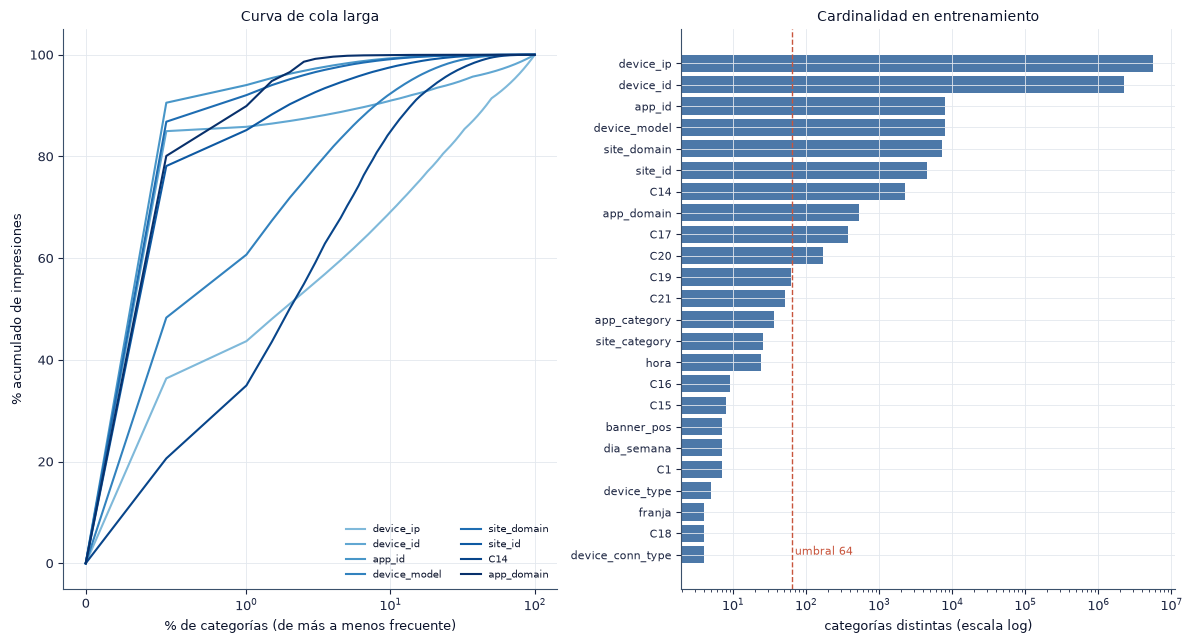

In [9]:
altas = perfil.sort_values("categorias", ascending=False)["variable"].head(8).tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5))
pal = plt.cm.Blues(np.linspace(0.45, 1, len(altas)))
for colr, v in zip(pal, altas):
    axes[0].plot(np.array(curvas[v]["x"]) * 100, np.array(curvas[v]["y"]) * 100, color=colr, label=v)
axes[0].set_xscale("symlog", linthresh=1); axes[0].set_xlabel("% de categorías (de más a menos frecuente)")
axes[0].set_ylabel("% acumulado de impresiones"); axes[0].set_title("Curva de cola larga"); axes[0].legend(fontsize=7, ncols=2)
pp = perfil.sort_values("categorias")
axes[1].barh(pp["variable"], pp["categorias"], color=C.BAR)
axes[1].tick_params(axis="y", labelsize=8); axes[1].set_xscale("log"); axes[1].set_xlabel("categorías distintas (escala log)"); axes[1].set_title("Cardinalidad en entrenamiento")
axes[1].axvline(C.LOW_CARD_MAX, c=C.ACCENT, ls="--", lw=1); axes[1].text(C.LOW_CARD_MAX * 1.1, 0, f"umbral {C.LOW_CARD_MAX}", color=C.ACCENT, fontsize=8)
fig.tight_layout(); P.save(fig, "2_4_cola_larga"); plt.show()

In [10]:
top = perfil.sort_values("categorias", ascending=False).iloc[0]
ids = ["device_id", "device_ip", "device_model", "site_id", "site_domain", "app_id", "app_domain"]
dom = perfil[perfil["variable"].isin(ids)].sort_values("cuota_top1", ascending=False).iloc[0]
frase_dom = (f"Entre las variables de identificadores, `{dom['variable']}` concentra {R.pct(dom['cuota_top1'])} de las impresiones "
             f"en un solo valor (`{dom['valor_mas_frecuente']}`), un patrón compatible con un valor por defecto cuando el "
             "identificador no está disponible." if dom["cuota_top1"] > 0.5 else
             f"Ningún identificador concentra más de la mitad de las impresiones; el valor más repetido es `{dom['valor_mas_frecuente']}` "
             f"de `{dom['variable']}`, con {R.pct(dom['cuota_top1'])}.")
riesgo_dom = (f"el valor dominante de `{dom['variable']}` funciona como un faltante codificado; el modelo puede aprender que su "
              "presencia o ausencia se asocia con el clic." if dom["cuota_top1"] > 0.5 else
              "las categorías que aparecen en prueba y no en entrenamiento se representan como `__RARE__`; su proporción condiciona la generalización.")
R.findings(
    f"La variable de mayor cardinalidad es `{top['variable']}`, con {R.num(top['categorias'])} categorías, de las cuales "
    f"{R.pct(top['vistas_una_vez'])} aparecen una sola vez. En el otro extremo, {int((perfil['categorias'] <= C.LOW_CARD_MAX).sum())} variables "
    f"tienen como máximo {C.LOW_CARD_MAX} categorías. " + frase_dom,
    {"Preprocesamiento": f"agrupamos en `{C.RARE_TOKEN}` las categorías con menos de {C.RARE_MIN_COUNT} apariciones en entrenamiento; "
                         "el umbral se cuenta en cada muestra de entrenamiento, nunca con validación ni prueba.",
     "Modelado": "un one-hot de las variables de identificadores produciría millones de columnas; por eso la codificación de alta cardinalidad es un factor experimental (hashing, frecuencia y target encoding).",
     "Riesgos": riesgo_dom})

### Hallazgos y decisiones

La variable de mayor cardinalidad es `device_ip`, con 5 566 572 categorías, de las cuales 49.9 % aparecen una sola vez. En el otro extremo, 14 variables tienen como máximo 64 categorías. Entre las variables de identificadores, `device_id` concentra 82.6 % de las impresiones en un solo valor (`a99f214a`), un patrón compatible con un valor por defecto cuando el identificador no está disponible.

- **Preprocesamiento:** agrupamos en `__RARE__` las categorías con menos de 10 apariciones en entrenamiento; el umbral se cuenta en cada muestra de entrenamiento, nunca con validación ni prueba.
- **Modelado:** un one-hot de las variables de identificadores produciría millones de columnas; por eso la codificación de alta cardinalidad es un factor experimental (hashing, frecuencia y target encoding).
- **Riesgos:** el valor dominante de `device_id` funciona como un faltante codificado; el modelo puede aprender que su presencia o ausencia se asocia con el clic.


## 2.5 Frecuencias de las principales categóricas

Mostramos las categorías más frecuentes de seis variables de baja cardinalidad, con su participación en las impresiones y su CTR.

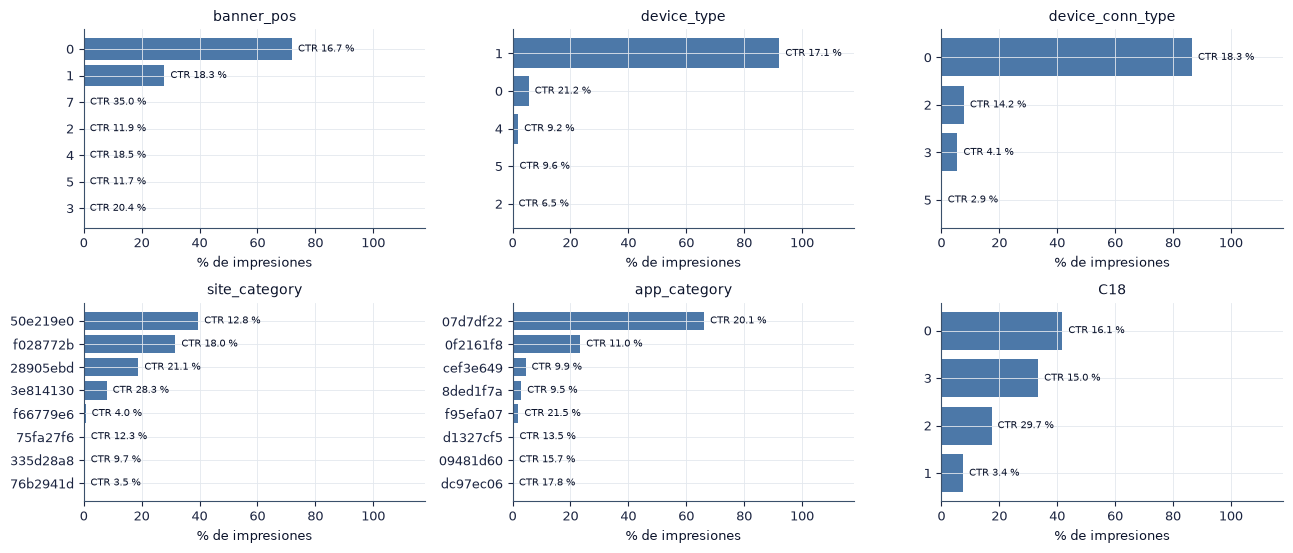

,categoría principal,cuota,CTR mín (top 8),CTR máx (top 8)
variable,,,,
banner_pos,0,0.7195,0.1175,0.3497
device_type,1,0.9215,0.0645,0.2116
device_conn_type,0,0.8656,0.0294,0.1826
site_category,50e219e0,0.3955,0.0352,0.2832
app_category,07d7df22,0.6617,0.0949,0.2153
C18,0,0.4177,0.0344,0.2965


In [11]:
vars_ = ["banner_pos", "device_type", "device_conn_type", "site_category", "app_category", "C18"]
fig, axes = plt.subplots(2, 3, figsize=(13, 5.6))
resumen = []
for ax, v in zip(axes.ravel(), vars_):
    t = c.execute(f"SELECT {v} AS cat, count(*) AS n, avg(click) AS ctr FROM train GROUP BY 1 ORDER BY n DESC LIMIT 8").df()
    t["cuota"] = t["n"] / n_tr
    ax.barh(t["cat"][::-1], 100 * t["cuota"][::-1], color=C.BAR)
    for y, (q, r) in enumerate(zip(t["cuota"][::-1], t["ctr"][::-1])):
        ax.text(100 * q, y, f"  CTR {100 * r:.1f} %", va="center", fontsize=7)
    ax.set_title(v); ax.set_xlabel("% de impresiones"); ax.set_xlim(0, 118)
    resumen.append({"variable": v, "categoría principal": t["cat"].iat[0], "cuota": t["cuota"].iat[0],
                    "CTR mín (top 8)": t["ctr"].min(), "CTR máx (top 8)": t["ctr"].max()})
fig.tight_layout(); P.save(fig, "2_5_frecuencias"); plt.show()
resumen = pd.DataFrame(resumen)
R.tabla(resumen, "variable", 4)

In [12]:
amp = resumen.assign(rango=resumen["CTR máx (top 8)"] - resumen["CTR mín (top 8)"]).sort_values("rango", ascending=False).iloc[0]
R.findings(
    f"En todas las variables una categoría concentra la mayor parte de las impresiones. Aun así, el CTR cambia entre categorías: "
    f"en `{amp['variable']}` va de {R.pct(amp['CTR mín (top 8)'])} a {R.pct(amp['CTR máx (top 8)'])} entre sus ocho categorías más frecuentes.",
    {"Preprocesamiento": "las categorías poco frecuentes con CTR extremo se estiman con ruido; la agrupación en `__RARE__` limita ese ruido.",
     "Modelado": "las diferencias de CTR entre categorías de baja cardinalidad son información útil incluso para un modelo lineal.",
     "Riesgos": "una categoría dominante reduce la variedad efectiva de la variable: buena parte del aprendizaje depende de pocas categorías minoritarias."})

### Hallazgos y decisiones

En todas las variables una categoría concentra la mayor parte de las impresiones. Aun así, el CTR cambia entre categorías: en `C18` va de 3.4 % a 29.7 % entre sus ocho categorías más frecuentes.

- **Preprocesamiento:** las categorías poco frecuentes con CTR extremo se estiman con ruido; la agrupación en `__RARE__` limita ese ruido.
- **Modelado:** las diferencias de CTR entre categorías de baja cardinalidad son información útil incluso para un modelo lineal.
- **Riesgos:** una categoría dominante reduce la variedad efectiva de la variable: buena parte del aprendizaje depende de pocas categorías minoritarias.


## 2.6 Variables numéricas derivadas

Avazu no trae variables numéricas continuas. Las únicas que construimos son las frecuencias de las categorías, que usa la codificación por frecuencia: para cada variable de alta cardinalidad, el número de veces que su valor aparece en entrenamiento. Comparamos su distribución antes y después de aplicar $\log(1 + n)$, en una muestra de entrenamiento del tamaño principal.

,site_id,site_domain,app_id,app_domain,device_id,device_ip,device_model,C14,C17,C20
asimetría de n,0.30,0.26,-0.64,-0.84,-1.72,-1.07,2.15,0.77,1.91,0.13
asimetría de log(1+n),-0.97,-1.14,-1.27,-1.64,-6.39,-1.23,-0.56,-0.96,-0.43,-0.80


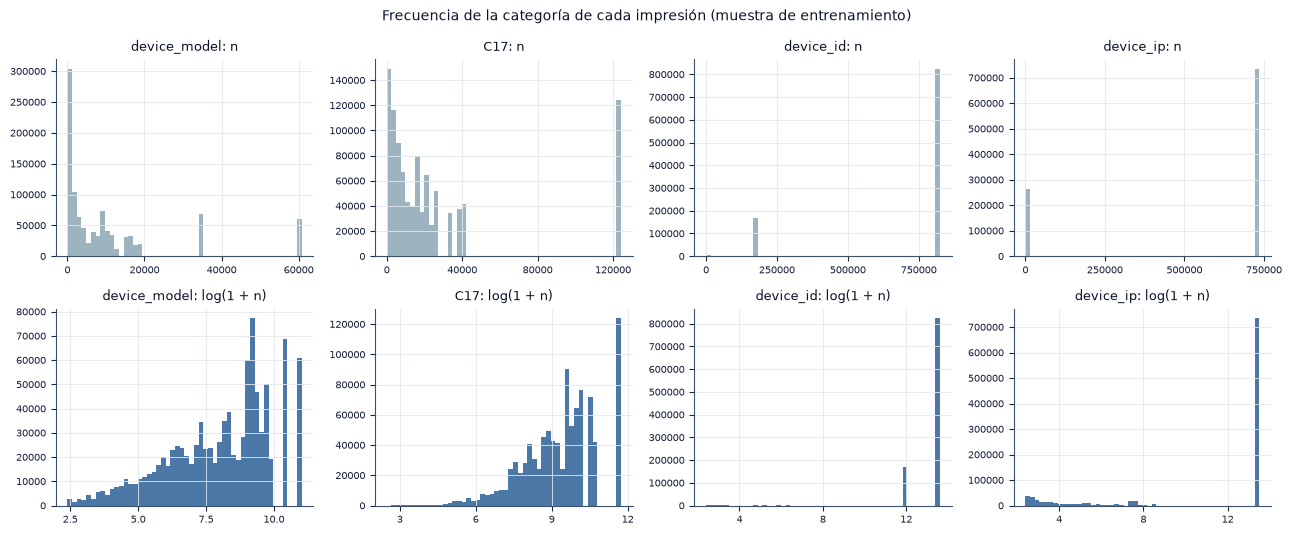

In [13]:
grupos = E.column_groups(c) if not (C.COMMON / "column_groups.json").exists() else C.column_groups()
mtr = D.load_train(C.SIZES[C.MAIN_SIZE])
pf = F.CTRPreprocessor("freq", groups=grupos)
pf.fit(mtr, D.y_of(mtr))
g = pf.rare_.transform(mtr.select(pf.cols))
cnt = pd.DataFrame({v: g.select(v).join(pf.counts_[v], on=v, how="left", maintain_order="left")["n"].to_numpy() for v in pf.high})
from scipy.stats import skew
asim = pd.DataFrame({"asimetría de n": cnt.apply(lambda s: skew(s)), "asimetría de log(1+n)": np.log1p(cnt).apply(lambda s: skew(s))})
display(asim.round(2).T)

show_vars = asim["asimetría de n"].abs().sort_values(ascending=False).index[:4].tolist()
fig, axes = plt.subplots(2, 4, figsize=(13, 5.4))
for j, v in enumerate(show_vars):
    axes[0, j].hist(cnt[v], bins=50, color="#9DB4C0"); axes[0, j].set_title(f"{v}: n", fontsize=9)
    axes[1, j].hist(np.log1p(cnt[v]), bins=50, color=C.BAR); axes[1, j].set_title(f"{v}: log(1 + n)", fontsize=9)
from matplotlib.ticker import MaxNLocator
for ax_ in axes.ravel():
    ax_.xaxis.set_major_locator(MaxNLocator(4)); ax_.tick_params(labelsize=7)
fig.suptitle("Frecuencia de la categoría de cada impresión (muestra de entrenamiento)", fontsize=10)
fig.tight_layout(); P.save(fig, "2_6_histogramas"); plt.show()

In [14]:
a0, a1 = asim["asimetría de n"].abs().mean(), asim["asimetría de log(1+n)"].abs().mean()
R.findings(
    f"La asimetría media (en valor absoluto) de las frecuencias $n$ es {a0:.1f}; con $\\log(1 + n)$ es {a1:.1f}. "
    + ("La transformación reduce la asimetría y comprime la escala de las categorías muy frecuentes." if a1 < a0 else
       "La transformación no reduce la asimetría media en esta muestra, pero sí comprime la escala de las categorías muy frecuentes."),
    {"Preprocesamiento": "en la estrategia de frecuencia aplicamos $\\log(1+n)$ y después `StandardScaler`, ambos ajustados solo con entrenamiento.",
     "Modelado": "sin la transformación, unas pocas categorías dominarían la escala de la entrada y el MLP con ReLU recibiría activaciones muy grandes.",
     "Riesgos": "la frecuencia confunde categorías distintas con el mismo conteo; esa pérdida de información es parte de lo que mide P2."})

### Hallazgos y decisiones

La asimetría media (en valor absoluto) de las frecuencias $n$ es 1.0; con $\log(1 + n)$ es 1.5. La transformación no reduce la asimetría media en esta muestra, pero sí comprime la escala de las categorías muy frecuentes.

- **Preprocesamiento:** en la estrategia de frecuencia aplicamos $\log(1+n)$ y después `StandardScaler`, ambos ajustados solo con entrenamiento.
- **Modelado:** sin la transformación, unas pocas categorías dominarían la escala de la entrada y el MLP con ReLU recibiría activaciones muy grandes.
- **Riesgos:** la frecuencia confunde categorías distintas con el mismo conteo; esa pérdida de información es parte de lo que mide P2.


## 2.7 Asociación con el objetivo y entre variables

Medimos la asociación de cada variable (con las categorías raras ya agrupadas) con el clic mediante:

- **Información mutua** $I(X; Y) = \sum_{x, y} p(x, y) \log_2 \frac{p(x, y)}{p(x) p(y)}$, en bits. La normalizamos por la entropía del objetivo $H(Y)$, de modo que vale 0 si la variable no aporta información y 1 si determina el clic. La información mutua crece con el número de categorías, por lo que favorece a las variables de alta cardinalidad.
- **V de Cramér** $V = \sqrt{\chi^2 / N}$ para la tabla de contingencia variable × clic (con dos clases, $\min(r, c) - 1 = 1$).

Para la relación entre variables usamos la correlación de rangos de Spearman entre las frecuencias logarítmicas de las variables de alta cardinalidad y el clic, en la muestra de la sección 2.6.

variable,device_ip,site_id,C14,C17,site_domain,app_id,C21,device_model,C19,C18,...,device_id,app_category,C15,device_conn_type,C1,device_type,dia_semana,banner_pos,hora,franja
mi_bits,0.0560,0.0524,0.0520,0.0490,0.0468,0.0323,0.0315,0.0258,0.0251,0.0229,...,0.0116,0.0106,0.0105,0.0076,0.0014,0.0013,0.0006,0.0004,0.0003,0.0002
mi_normalizada,0.0847,0.0793,0.0787,0.0742,0.0707,0.0489,0.0477,0.0390,0.0380,0.0346,...,0.0175,0.0160,0.0159,0.0115,0.0022,0.0019,0.0009,0.0006,0.0005,0.0002
v_cramer,0.2538,0.2781,0.2698,0.2622,0.2623,0.1916,0.2027,0.1776,0.1770,0.1742,...,0.1140,0.1169,0.1333,0.0897,0.0424,0.0404,0.0283,0.0243,0.0217,0.0146
categorias,414617.0000,3007.0000,2073.0000,367.0000,3296.0000,3727.0000,52.0000,5720.0000,62.0000,4.0000,...,78279.0000,28.0000,8.0000,4.0000,7.0000,5.0000,7.0000,7.0000,24.0000,4.0000


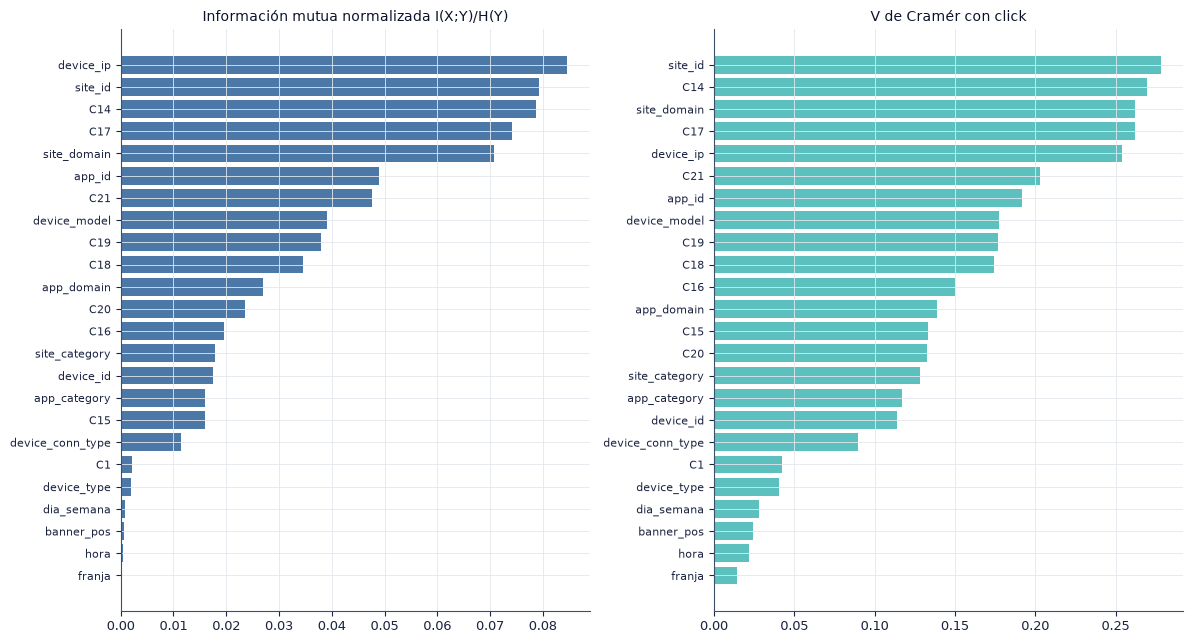

In [15]:
as_path = OUT / "asociacion.csv"
if as_path.exists():
    asoc = pd.read_csv(as_path)
else:
    asoc = pd.DataFrame([E.association(c, v) for v in C.CAT_COLS]).sort_values("mi_normalizada", ascending=False)
    asoc.to_csv(as_path, index=False)
display(asoc.round(4).set_index("variable").T)

fig, axes = plt.subplots(1, 2, figsize=(12, 6.5))
a = asoc.sort_values("mi_normalizada")
axes[0].barh(a["variable"], a["mi_normalizada"], color=C.BAR); axes[0].set_title("Información mutua normalizada I(X;Y)/H(Y)")
a = asoc.sort_values("v_cramer")
axes[1].barh(a["variable"], a["v_cramer"], color="#5BC0BE"); axes[1].set_title("V de Cramér con click")
for ax_ in axes:
    ax_.tick_params(axis="y", labelsize=8)
fig.tight_layout(); P.save(fig, "2_7_asociacion"); plt.show()

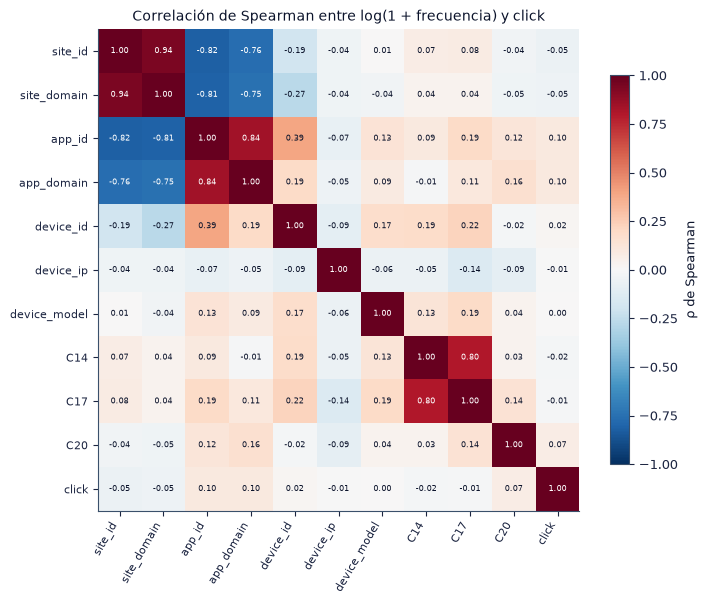

In [16]:
lf_cols = {v: f"log_n_{v}" for v in pf.high}
M = np.log1p(cnt).rename(columns=lf_cols)
M["click"] = D.y_of(mtr)
rho = M.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(rho, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(rho)), [s.replace("log_n_", "") for s in rho.columns], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(rho)), [s.replace("log_n_", "") for s in rho.index], fontsize=8)
for i in range(len(rho)):
    for j in range(len(rho)):
        ax.text(j, i, f"{rho.iat[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(rho.iat[i, j]) > 0.6 else "#0B132B")
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8, label="ρ de Spearman")
ax.set_title("Correlación de Spearman entre log(1 + frecuencia) y click")
fig.tight_layout(); P.save(fig, "2_7_spearman"); plt.show()

In [17]:
tri = rho.drop(index="click", columns="click").where(np.triu(np.ones((len(pf.high),) * 2, bool), 1)).stack()
par = tri.abs().idxmax()
top3 = asoc.sort_values("mi_normalizada", ascending=False)["variable"].head(3).tolist()
topv = asoc.sort_values("v_cramer", ascending=False)["variable"].head(3).tolist()
R.findings(
    f"Las variables con mayor información mutua normalizada son {', '.join(f'`{v}`' for v in top3)}; por V de Cramér, "
    f"{', '.join(f'`{v}`' for v in topv)}. "
    + (f"Las asociaciones individuales son débiles (V máximo de {asoc['v_cramer'].max():.3f}), lo esperable cuando el clic depende de combinaciones de variables. "
       if asoc["v_cramer"].max() < 0.3 else f"La asociación individual más fuerte alcanza V = {asoc['v_cramer'].max():.3f}. ")
    + f"La correlación más alta en valor absoluto entre frecuencias es la de "
    f"`{par[0].replace('log_n_', '')}` con `{par[1].replace('log_n_', '')}` (ρ = {tri[par]:.2f}).",
    {"Preprocesamiento": "conservamos todas las variables: la redundancia entre identificadores de un mismo origen (sitio, aplicación) no afecta al MLP y la penalización L2 la controla en la regresión logística.",
     "Modelado": "las asociaciones individuales débiles justifican un modelo capaz de representar interacciones, como el MLP o los árboles potenciados; los cruces de variables se evalúan como ablación.",
     "Riesgos": "la información mutua de las variables de alta cardinalidad está inflada por el número de categorías; no la usamos para seleccionar variables."})

### Hallazgos y decisiones

Las variables con mayor información mutua normalizada son `device_ip`, `site_id`, `C14`; por V de Cramér, `site_id`, `C14`, `site_domain`. Las asociaciones individuales son débiles (V máximo de 0.278), lo esperable cuando el clic depende de combinaciones de variables. La correlación más alta en valor absoluto entre frecuencias es la de `site_id` con `site_domain` (ρ = 0.94).

- **Preprocesamiento:** conservamos todas las variables: la redundancia entre identificadores de un mismo origen (sitio, aplicación) no afecta al MLP y la penalización L2 la controla en la regresión logística.
- **Modelado:** las asociaciones individuales débiles justifican un modelo capaz de representar interacciones, como el MLP o los árboles potenciados; los cruces de variables se evalúan como ablación.
- **Riesgos:** la información mutua de las variables de alta cardinalidad está inflada por el número de categorías; no la usamos para seleccionar variables.


## 2.8 Deriva entre entrenamiento y prueba

El índice de estabilidad poblacional compara la distribución de una variable en entrenamiento (esperada, $e_b$) y en prueba (observada, $o_b$) sobre las mismas categorías $b$:

$$\text{PSI} = \sum_{b} (o_b - e_b) \ln \frac{o_b}{e_b}.$$

Usamos las 20 categorías más frecuentes en entrenamiento más una categoría "resto". La convención habitual interpreta PSI < 0.1 como estable, entre 0.1 y 0.25 como deriva moderada y > 0.25 como deriva alta (Yurdakul, 2018). Esta prueba usa solo las variables de entrada del día 30, no su etiqueta.

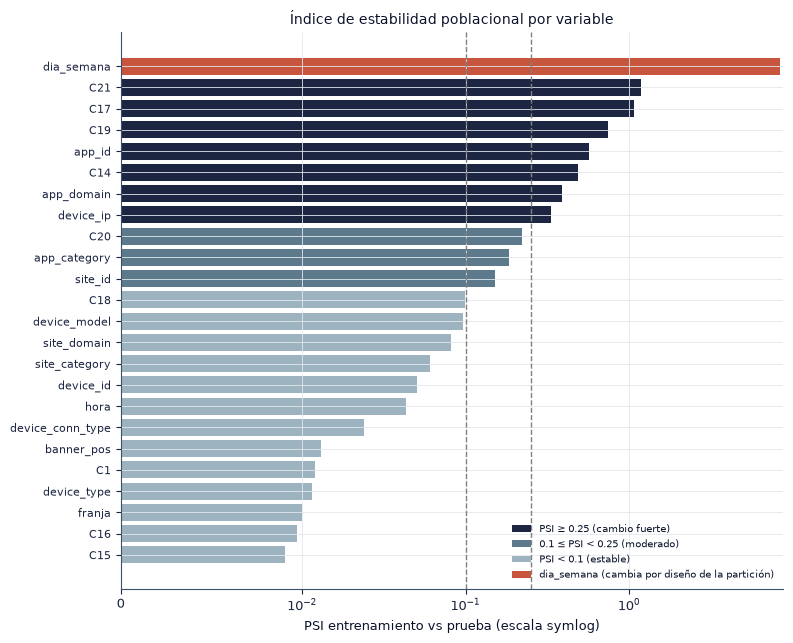

variable,dia_semana,C21,C17,C19,app_id,C14,app_domain,device_ip,C20,app_category,...,site_category,device_id,hora,device_conn_type,banner_pos,C1,device_type,franja,C16,C15
psi,8.3669,1.1879,1.0757,0.7463,0.5725,0.4866,0.3903,0.3327,0.2231,0.1841,...,0.0608,0.0507,0.0435,0.0238,0.0131,0.0119,0.0115,0.01,0.0097,0.009
nivel,alta,alta,alta,alta,alta,alta,alta,alta,moderada,moderada,...,estable,estable,estable,estable,estable,estable,estable,estable,estable,estable


In [18]:
psi_path = OUT / "psi.csv"
if psi_path.exists():
    psi = pd.read_csv(psi_path)
else:
    psi = pd.DataFrame([E.psi(c, v) for v in C.CAT_COLS]).sort_values("psi", ascending=False)
    psi.to_csv(psi_path, index=False)
psi["nivel"] = psi["psi"].map(E.psi_label)

fig, ax = plt.subplots(figsize=(8, 6.5))
p_ = psi.sort_values("psi")
cols = [C.ACCENT if v == "dia_semana" else ("#1C2541" if x >= 0.25 else ("#5C7A8C" if x >= 0.1 else "#9DB4C0")) for v, x in zip(p_["variable"], p_["psi"])]
ax.barh(p_["variable"], p_["psi"], color=cols)
for x in (0.1, 0.25):
    ax.axvline(x, ls="--", c="gray", lw=1)
ax.set_xscale("symlog", linthresh=0.01); ax.set_xlabel("PSI entrenamiento vs prueba (escala symlog)")
ax.set_title("Índice de estabilidad poblacional por variable"); ax.tick_params(axis="y", labelsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor="#1C2541", label="PSI ≥ 0.25 (cambio fuerte)"), Patch(facecolor="#5C7A8C", label="0.1 ≤ PSI < 0.25 (moderado)"),
                   Patch(facecolor="#9DB4C0", label="PSI < 0.1 (estable)"), Patch(facecolor=C.ACCENT, label="dia_semana (cambia por diseño de la partición)")],
          fontsize=7, loc="lower right")
fig.tight_layout(); P.save(fig, "2_8_psi"); plt.show()
display(psi.round(4).set_index("variable").T)

In [19]:
deriva = psi[(psi["psi"] >= 0.1) & (psi["variable"] != "dia_semana")]
R.findings(
    f"`dia_semana` presenta el PSI más alto por construcción: el día de prueba es un solo día de la semana. Fuera de ella, "
    + (f"{len(deriva)} variables muestran deriva moderada o alta: {', '.join(f'`{v}` ({x:.2f})' for v, x in zip(deriva['variable'], deriva['psi']))}."
       if len(deriva) else "ninguna variable supera el umbral de deriva moderada (0.1).")
    + f" El resto tiene PSI menor que 0.1.",
    {"Preprocesamiento": "la partición temporal es obligatoria: una partición aleatoria mezclaría los días y ocultaría esta deriva, con lo que sobreestimaría el desempeño.",
     "Modelado": "las categorías nuevas del día de prueba caen en `__RARE__` o, con hashing, en columnas compartidas; el modelo debe generalizar a valores no vistos.",
     "Riesgos": "la deriva afecta más a la calibración que al ordenamiento; por eso evaluamos el ECE y la curva de calibración en el día de prueba."})

### Hallazgos y decisiones

`dia_semana` presenta el PSI más alto por construcción: el día de prueba es un solo día de la semana. Fuera de ella, 10 variables muestran deriva moderada o alta: `C21` (1.19), `C17` (1.08), `C19` (0.75), `app_id` (0.57), `C14` (0.49), `app_domain` (0.39), `device_ip` (0.33), `C20` (0.22), `app_category` (0.18), `site_id` (0.15). El resto tiene PSI menor que 0.1.

- **Preprocesamiento:** la partición temporal es obligatoria: una partición aleatoria mezclaría los días y ocultaría esta deriva, con lo que sobreestimaría el desempeño.
- **Modelado:** las categorías nuevas del día de prueba caen en `__RARE__` o, con hashing, en columnas compartidas; el modelo debe generalizar a valores no vistos.
- **Riesgos:** la deriva afecta más a la calibración que al ordenamiento; por eso evaluamos el ECE y la curva de calibración en el día de prueba.


## 2.9 Partición temporal y grupos de variables

La partición es cronológica: entrenamiento con los días 21 a 28, validación con el día 29 y prueba con el día 30. Las muestras escalonadas de entrenamiento salen de los días 21 a 28 con la clave $u$. El conjunto de prueba queda congelado: su huella SHA-256 está en el manifiesto y el código la verifica antes de cada evaluación.

Clasificamos las variables según su cardinalidad tras agrupar las raras, contada en la ventana de entrenamiento completa: las de baja cardinalidad reciben one-hot en las estrategias densas y las de alta cardinalidad reciben la codificación que se compara en P2.

In [20]:
grupos = C.column_groups()
part = pd.DataFrame({
    "partición": ["entrenamiento", "validación", "prueba"],
    "días": [f"{C.TRAIN_DAYS[0]}–{C.TRAIN_DAYS[-1]}", str(C.VAL_DAY), str(C.TEST_DAY)],
    "filas disponibles": [D.window_rows(C.TRAIN_DAYS), D.window_rows([C.VAL_DAY]), D.window_rows([C.TEST_DAY])],
    "filas usadas": [", ".join(f"{k}" for k in C.SIZES), R.num(min(C.VAL_ROWS, D.window_rows([C.VAL_DAY]))), "todas"],
})
display(part.set_index("partición"))
card = pd.Series(grupos["cardinalidad_tras_raras"], name="cardinalidad tras agrupar").to_frame()
card["grupo"] = np.where(card.index.isin(grupos["baja"]), "baja (one-hot)", "alta (factor experimental)")
display(card.sort_values("cardinalidad tras agrupar").T)
D.verify_test_frozen()
print("Huella del conjunto de prueba verificada.")

,días,filas disponibles,filas usadas
partición,,,
entrenamiento,21–28,32377421,"100k, 1M, 3M, 10M"
validación,29,3832608,1 000 000
prueba,30,4218938,todas


,device_conn_type,C18,franja,device_type,C1,dia_semana,banner_pos,C15,C16,site_category,...,C20,app_domain,C17,C14,site_id,site_domain,app_id,device_model,device_id,device_ip
cardinalidad tras agrupar,4,4,4,5,7,7,7,8,9,23,...,166,236,367,2073,3007,3296,3727,5720,78279,414617
grupo,baja (one-hot),baja (one-hot),baja (one-hot),baja (one-hot),baja (one-hot),baja (one-hot),baja (one-hot),baja (one-hot),baja (one-hot),baja (one-hot),...,alta (factor experimental),alta (factor experimental),alta (factor experimental),alta (factor experimental),alta (factor experimental),alta (factor experimental),alta (factor experimental),alta (factor experimental),alta (factor experimental),alta (factor experimental)


Huella del conjunto de prueba verificada.


In [21]:
R.findings(
    f"Quedan {len(grupos['baja'])} variables de baja cardinalidad y {len(grupos['alta'])} de alta cardinalidad. "
    f"La muestra principal de entrenamiento tiene {R.num(C.SIZES[C.MAIN_SIZE])} filas y la de validación {R.num(min(C.VAL_ROWS, D.window_rows([C.VAL_DAY])))}.",
    {"Preprocesamiento": "todos los modelos, en ambos entornos, usan estas particiones y estos grupos de variables.",
     "Modelado": "la parada temprana interna de `MLPClassifier` separa su propia validación dentro de la ventana de entrenamiento; la selección de hiperparámetros y del umbral usa el día 29.",
     "Riesgos": "un solo día de validación y uno de prueba reflejan las condiciones de esos días; no estiman la variación del desempeño entre días."},
    titulo="Hallazgos y decisiones")
c.close()

### Hallazgos y decisiones

Quedan 14 variables de baja cardinalidad y 10 de alta cardinalidad. La muestra principal de entrenamiento tiene 1 000 000 filas y la de validación 1 000 000.

- **Preprocesamiento:** todos los modelos, en ambos entornos, usan estas particiones y estos grupos de variables.
- **Modelado:** la parada temprana interna de `MLPClassifier` separa su propia validación dentro de la ventana de entrenamiento; la selección de hiperparámetros y del umbral usa el día 29.
- **Riesgos:** un solo día de validación y uno de prueba reflejan las condiciones de esos días; no estiman la variación del desempeño entre días.
